# Moment Retrieval — Timestamp Evaluation

This notebook evaluates how well the predicted timestamps from the moment retrieval model align with the human-annotated ground truth intervals. It reads prediction JSON files from `Timestamps/` and annotation files from `Annotations/`, computes interval-based metrics, saves results to `Evaluations/`, and produces timeline visualisations.

**Run order:** cells must be run top to bottom. Cells 1–4 define all helpers and only need to be run once per session. Cell 5 is the main pipeline and can be re-run after new predictions are added. Cells 6–7 are for inspection and can be re-run freely.

### 1. Imports and configuration

Loads dependencies and sets directory paths. `VIDEO_IDS` controls which videos are processed.

In [34]:
import json
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from pathlib import Path

ANNOTATIONS_DIR = Path("Annotations")
TIMESTAMPS_DIR  = Path("Timestamps")
EVAL_DIR        = Path("Evaluations")
EVAL_DIR.mkdir(exist_ok=True)

VIDEO_IDS = [25, 26, 27, 28]

### 2. Parsers

- `parse_timestamp_str` / `parse_timestamp_range` — convert `MM:SS` annotation strings to seconds
- `load_annotations` — reads ground truth from `Annotations/GroundTruthVideo{id}.csv` or `.txt`
- `parse_predictions` — reads moment retrieval output from `Timestamps/video_{id}_with_predictions.json`, supporting both the current list format and the legacy column-oriented dict format
- `make_combo_key` — builds a canonical string key for a (vlm\_source, frame\_count, llm\_prompt) combination

In [35]:
# Parsers

def parse_timestamp_str(ts_str):
    ts_str = ts_str.strip()
    parts  = ts_str.split(":")
    return int(parts[0]) * 60 + float(parts[1])


def parse_timestamp_range(ts_range):
    ts_range = re.sub(r"\s*-\s*", "-", ts_range.strip())
    parts    = re.split(r"-(?=\d{2}:)", ts_range)
    if len(parts) != 2:
        raise ValueError(f"Cannot parse: '{ts_range}'")
    return parse_timestamp_str(parts[0]), parse_timestamp_str(parts[1])


def load_annotations(video_id):
    for name in [f"GroundTruthVideo{video_id}", f"video_{video_id}"]:
        for ext in ["csv", "txt"]:
            f = ANNOTATIONS_DIR / f"{name}.{ext}"
            if f.exists():
                df = pd.read_csv(f)
                annotations = []
                for _, row in df.iterrows():
                    try:
                        start, end = parse_timestamp_range(str(row["timestamp"]))
                        annotations.append({
                            "annotation":   row["annotation"],
                            "start":        start,
                            "end":          end,
                            "subjectivity": int(row["subjectivity_rating"]),
                        })
                    except Exception as e:
                        print(f"  Warning: skipping row — {e}")
                return annotations
    print(f"  Warning: no annotation file for video_{video_id}")
    return []


def parse_predictions(video_id):
    """Parse the predictions JSON — supports both list and column-oriented formats."""
    json_file = TIMESTAMPS_DIR / f"video_{video_id}_with_predictions.json"
    if not json_file.exists():
        print(f"  Warning: no predictions file for video_{video_id}")
        return []

    with open(json_file, "r") as f:
        raw = json.load(f)

    def parse_ts_list(ts_list):
        return [(t[0], t[1]) for t in ts_list]

    # new format: list of objects
    if isinstance(raw, list):
        return [{
            "prompt_type":     e["prompt_type"],
            "vlm_source":      e["vlm_source"],
            "vlm_frame_count": e["vlm_frame_count"],
            "queries":         e["parsed_events"],
            "chunks":          parse_ts_list(e["predicted_timestamps_chunks"]),
            "sped_up":         parse_ts_list(e["predicted_timestamps_sped_up"]),
        } for e in raw]

    # old format: column-oriented dict
    return [{
        "prompt_type":     raw["prompt_type"][str(i)],
        "vlm_source":      raw["vlm_source"][str(i)],
        "vlm_frame_count": raw["vlm_frame_count"][str(i)],
        "queries":         raw["parsed_events"][str(i)],
        "chunks":          parse_ts_list(raw["predicted_timestamps_chunks"][str(i)]),
        "sped_up":         parse_ts_list(raw["predicted_timestamps_sped_up"][str(i)]),
    } for i in range(len(raw["prompt_type"]))]

def make_combo_key(prompt_type, vlm_source, vlm_frame_count):
    return f"vlm={vlm_source}__frames={vlm_frame_count}__llm={prompt_type}"


print("Parsers loaded")

Parsers loaded


### 3. Metrics

All metrics operate on sets of `(start, end)` intervals in seconds.

- `merge_intervals` — merges overlapping intervals into a minimal non-overlapping set
- `total_duration` — sums the duration of a set of intervals
- `interval_intersection` — computes the total overlap duration between two sets of intervals
- `coverage_metrics` — given ground truth annotations and predicted intervals, computes:
  - **IoU** — intersection / union (primary metric)
  - **Coverage** — intersection / GT duration (recall-like)
  - **Precision** — intersection / predicted duration
  - **F1** — harmonic mean of coverage and precision

In [36]:
# Metrics

def merge_intervals(intervals):
    if not intervals:
        return []
    sorted_ivs = sorted(intervals, key=lambda x: x[0])
    merged = [list(sorted_ivs[0])]
    for start, end in sorted_ivs[1:]:
        if start <= merged[-1][1]:
            merged[-1][1] = max(merged[-1][1], end)
        else:
            merged.append([start, end])
    return [(s, e) for s, e in merged]


def total_duration(intervals):
    return sum(e - s for s, e in intervals)


def interval_intersection(ivs_a, ivs_b):
    total = 0.0
    for a_start, a_end in ivs_a:
        for b_start, b_end in ivs_b:
            total += max(0.0, min(a_end, b_end) - max(a_start, b_start))
    return total


def coverage_metrics(annotations, predicted_timestamps):
    """Compute IoU, coverage, precision and F1 of predicted vs GT intervals."""
    if not annotations or not predicted_timestamps:
        return None

    gt_intervals   = merge_intervals([(a["start"], a["end"]) for a in annotations])
    pred_intervals = merge_intervals(list(predicted_timestamps))

    gt_duration   = total_duration(gt_intervals)
    pred_duration = total_duration(pred_intervals)
    intersection  = interval_intersection(gt_intervals, pred_intervals)

    coverage  = intersection / gt_duration   if gt_duration   > 0 else 0.0
    precision = intersection / pred_duration if pred_duration > 0 else 0.0
    f1        = (2 * coverage * precision / (coverage + precision)
                 if (coverage + precision) > 0 else 0.0)
    union     = gt_duration + pred_duration - intersection
    iou       = intersection / union if union > 0 else 0.0

    return {
        "gt_duration_sec":   round(gt_duration,  2),
        "pred_duration_sec": round(pred_duration, 2),
        "intersection_sec":  round(intersection,  2),
        "iou":               round(iou,       4),
        "coverage":          round(coverage,  4),
        "precision":         round(precision, 4),
        "f1":                round(f1,        4),
        "n_gt_annotations":  len(annotations),
    }


print("Metrics loaded")

Metrics loaded


### 4. Save and skip helpers

- `already_evaluated` — checks whether a (video, combo, strategy) triple has already been saved, to avoid re-running completed evaluations
- `save_eval` — appends a new evaluation result to `Evaluations/video_{id}_eval_time.json`

In [37]:
# Helpers for saving and skipping evaluations

def already_evaluated(video_id, combo_key, strategy):
    eval_file = EVAL_DIR / f"video_{video_id}_eval_time.json"  # ← was _mr_eval.json
    if not eval_file.exists():
        return False
    with open(eval_file, "r") as f:
        data = json.load(f)
    return any(
        e["combo_key"] == combo_key and e["mr_strategy"] == strategy
        for e in data.get("evaluations", [])
    )


def save_eval(video_id, combo_key, prompt_type, vlm_source,
              vlm_frame_count, strategy, metrics):
    eval_file = EVAL_DIR / f"video_{video_id}_eval_time.json"
    data = {"video_id": video_id, "evaluations": []}
    if eval_file.exists():
        with open(eval_file, "r") as f:
            data = json.load(f)

    data["evaluations"].append({
        "combo_key":       combo_key,
        "vlm_prompt_type": vlm_source,
        "vlm_frame_count": vlm_frame_count,
        "llm_prompt_type": prompt_type,
        "mr_strategy":     strategy,
        "metrics":         metrics,
    })

    with open(eval_file, "w") as f:
        json.dump(data, f, indent=2)
    print(f"    Saved → {eval_file}")


print("Save helpers loaded")

Save helpers loaded


### 5. Evaluation pipeline

Main loop — iterates over all videos and all prediction combos (VLM prompt type × frame count × LLM prompt type × retrieval strategy). For each combo, computes all four metrics against the full set of human annotations and saves the result. Already-completed combos are skipped automatically.

Re-run this cell after adding new prediction files to `Timestamps/`.

In [38]:
# Evaluation pipeline

for video_id in VIDEO_IDS:
    print(f"\n{'='*60}\n  video_{video_id}\n{'='*60}")

    annotations = load_annotations(video_id)
    if not annotations:
        print("  No annotations, skipping")
        continue

    mr_results = parse_predictions(video_id)
    if not mr_results:
        print("  No predictions, skipping")
        continue

    for result in mr_results:
        combo_key = make_combo_key(
            result["prompt_type"],
            result["vlm_source"],
            result["vlm_frame_count"]
        )
        print(f"\n  Combo: {combo_key}")

        for strategy in ["chunks", "sped_up"]:
            if already_evaluated(video_id, combo_key, strategy):
                print(f"    Skipping: {strategy} — already done")
                continue

            m = coverage_metrics(annotations, result[strategy])
            if not m:
                continue

            save_eval(video_id, combo_key, result["prompt_type"],
                      result["vlm_source"], result["vlm_frame_count"],
                      strategy, m)

            print(f"    Done: {strategy} → "
                  f"IoU={m['iou']:.3f} | coverage={m['coverage']:.3f} | "
                  f"precision={m['precision']:.3f} | f1={m['f1']:.3f}")

print("\n\nAll done!")


  video_25

  Combo: vlm=long__frames=50__llm=concise
    Skipping: chunks — already done
    Skipping: sped_up — already done

  video_26

  Combo: vlm=long__frames=50__llm=concise
    Skipping: chunks — already done
    Skipping: sped_up — already done

  video_27

  Combo: vlm=long__frames=50__llm=concise
    Skipping: chunks — already done
    Skipping: sped_up — already done

  video_28

  Combo: vlm=long__frames=50__llm=concise
    Skipping: chunks — already done
    Skipping: sped_up — already done


All done!


### 6. Summary table and rankings

Loads all saved evaluation results and aggregates them into a ranked summary table, averaged across all four videos and sorted by mean IoU. Prints the best-performing combination.

In [39]:
# Summary and ranking

def load_all_mr_evals():
    rows = []
    for video_id in VIDEO_IDS:
        eval_file = EVAL_DIR / f"video_{video_id}_eval_time.json"
        if not eval_file.exists():
            continue
        with open(eval_file, "r") as f:
            data = json.load(f)
        for e in data.get("evaluations", []):
            m = e.get("metrics")
            if not m:
                continue
            rows.append({
                "video_id":        video_id,
                "combo_key":       e["combo_key"],
                "vlm_prompt_type": e["vlm_prompt_type"],
                "vlm_frame_count": e["vlm_frame_count"],
                "llm_prompt_type": e["llm_prompt_type"],
                "mr_strategy":     e["mr_strategy"],
                "iou":             m["iou"],
                "coverage":        m["coverage"],
                "precision":       m["precision"],
                "f1":              m["f1"],
                "gt_duration":     m["gt_duration_sec"],
                "pred_duration":   m["pred_duration_sec"],
                "intersection":    m["intersection_sec"],
            })
    return pd.DataFrame(rows)


mr_df = load_all_mr_evals()

if mr_df.empty:
    print("No evaluations yet — run Section 5 first")
else:
    ranked = (
        mr_df.groupby(["vlm_prompt_type", "vlm_frame_count",
                       "llm_prompt_type", "mr_strategy"])
        .agg(
            avg_iou       =("iou",       "mean"),
            avg_coverage  =("coverage",  "mean"),
            avg_precision =("precision", "mean"),
            avg_f1        =("f1",        "mean"),
            n_videos      =("video_id",  "count"),
        )
        .reset_index()
        .sort_values("avg_iou", ascending=False)
    )
    ranked.index = range(1, len(ranked) + 1)
    print("=== Rankings (avg across videos, sorted by IoU) ===\n")
    print(ranked.to_string())
    best = ranked.iloc[0]
    print(f"\nBest IoU: vlm={best['vlm_prompt_type']} | "
          f"frames={best['vlm_frame_count']} | "
          f"llm={best['llm_prompt_type']} | "
          f"strategy={best['mr_strategy']}")

=== Rankings (avg across videos, sorted by IoU) ===

  vlm_prompt_type  vlm_frame_count llm_prompt_type mr_strategy   avg_iou  avg_coverage  avg_precision    avg_f1  n_videos
1            long               50         concise     sped_up  0.296175      0.733525        0.33415  0.454825         4
2            long               50         concise      chunks  0.267100      0.523325        0.37620  0.414975         4

Best IoU: vlm=long | frames=50 | llm=concise | strategy=sped_up


### 7. Timeline visualisation

Plots predicted segments against ground truth annotations for selected videos and combos. GT segments are coloured green where covered by predictions and red where missed.

**Configuration:**
- `INSPECT_COMBOS` — list of `(prompt_type, vlm_source, vlm_frame_count, strategy)` tuples to display. Leave empty `[]` to show all combos × both strategies.

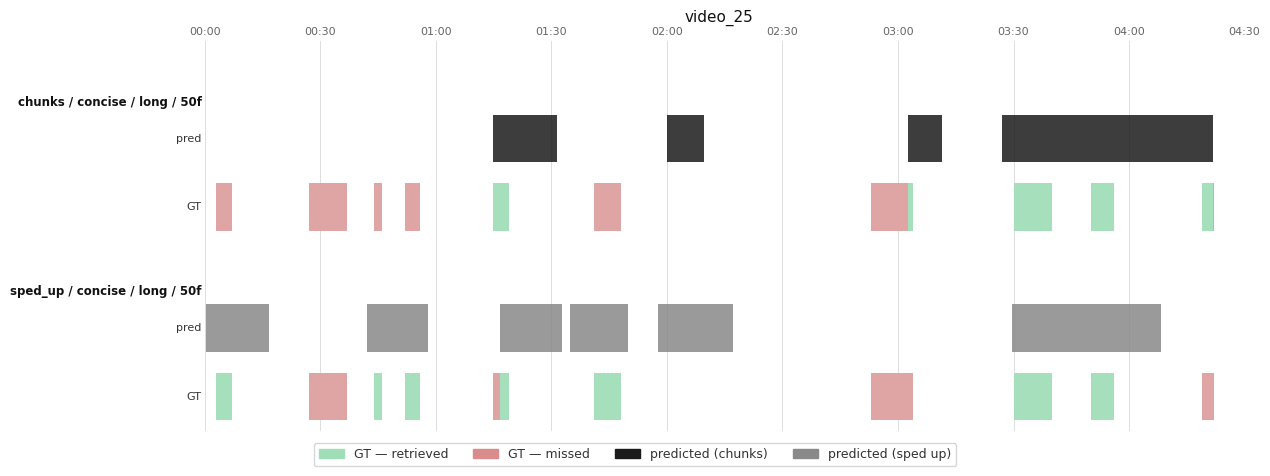

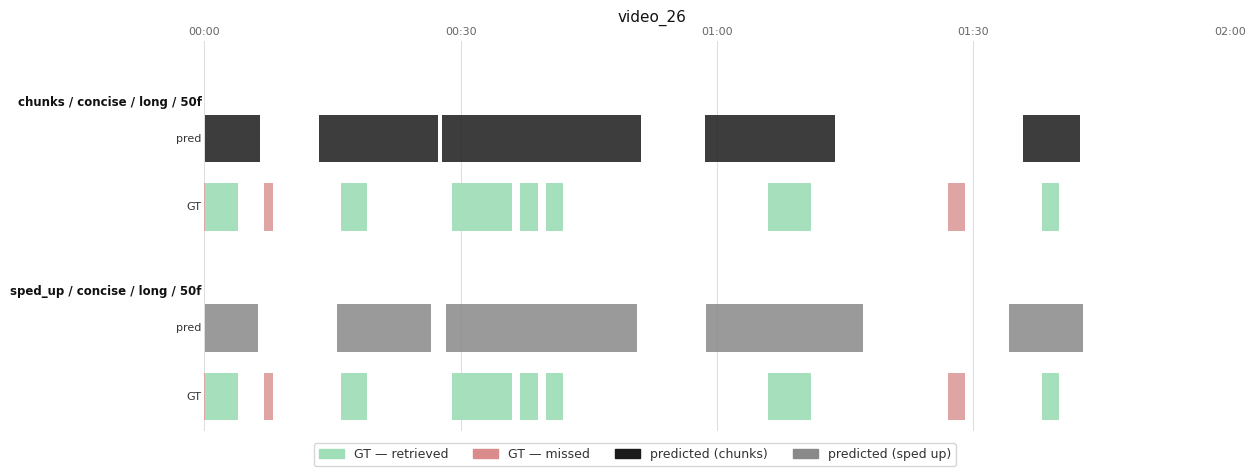

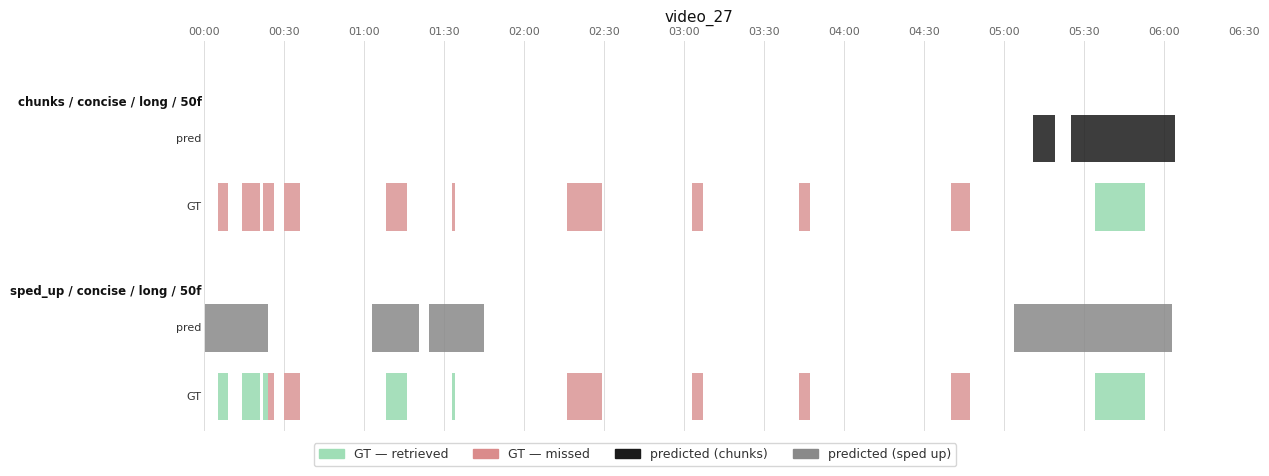

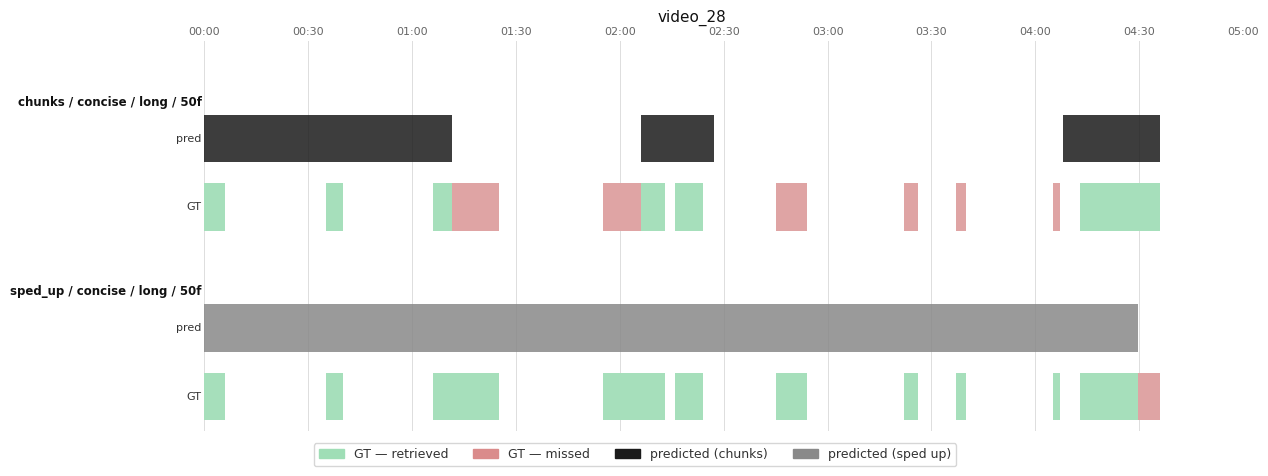

In [52]:
inspect_combos = globals().get("INSPECT_COMBOS", None)

for INSPECT_VIDEO_ID in VIDEO_IDS:
    annotations = load_annotations(INSPECT_VIDEO_ID)
    mr_results  = parse_predictions(INSPECT_VIDEO_ID)

    if not annotations or not mr_results:
        print(f"No data for video_{INSPECT_VIDEO_ID}, skipping")
        continue

    combos = inspect_combos if inspect_combos else [
        (r["prompt_type"], r["vlm_source"], r["vlm_frame_count"], s)
        for r in mr_results
        for s in ["chunks", "sped_up"]
    ]

    rows_to_plot = []
    for pt, vlm, frames, strategy in combos:
        match = next(
            (r for r in mr_results
             if r["prompt_type"] == pt
             and r["vlm_source"] == vlm
             and r["vlm_frame_count"] == frames),
            None
        )
        if match is None:
            print(f"  Warning: combo ({pt}, {vlm}, {frames}) not found, skipping")
            continue
        rows_to_plot.append((f"{strategy} / {pt} / {vlm} / {frames}f", match[strategy], strategy))

    if not rows_to_plot:
        continue

    all_ends = (
        [a["end"] for a in annotations]
        + [e for _, pred, _ in rows_to_plot for _, e in pred]
    )
    max_time = max(all_ends) * 1.02
    min_time = 0.0

    def pct(t):
        return (t - min_time) / (max_time - min_time)

    def covered_segments(gt_intervals, pred_intervals):
        pred_merged = merge_intervals(pred_intervals)
        covered, missed = [], []
        for gs, ge in gt_intervals:
            cursor = gs
            for ps, pe in pred_merged:
                overlap_s = max(cursor, ps)
                overlap_e = min(ge, pe)
                if overlap_s < overlap_e:
                    if cursor < overlap_s:
                        missed.append((cursor, overlap_s))
                    covered.append((overlap_s, overlap_e))
                    cursor = overlap_e
            if cursor < ge:
                missed.append((cursor, ge))
        return covered, missed

    row_h   = 0.45
    gap     = 0.2
    sec_gap = 0.5
    n_combos = len(rows_to_plot)
    fig_h   = max(3, 1.2 + n_combos * 2 * (row_h + gap) + n_combos * sec_gap)
    fig_w   = 16 * 0.8

    fig, ax = plt.subplots(figsize=(fig_w, fig_h))
    ax.set_facecolor("white")
    fig.patch.set_facecolor("white")

    tick_step = 30
    for t in range(0, int(max_time) + tick_step, tick_step):
        ax.axvline(pct(t), color="#dddddd", linewidth=0.7, zorder=0)
        ax.text(pct(t), 1.012,
                f"{int(t)//60:02d}:{int(t)%60:02d}",
                ha="center", va="bottom", fontsize=8,
                color="#666666", transform=ax.transAxes)

    row_y = 0.0

    def draw_row_label(y, text):
        ax.text(-0.003, y + row_h / 2, text,
                ha="right", va="center", fontsize=8,
                color="#333333", transform=ax.get_yaxis_transform())

    def draw_section_title(y, text):
        ax.text(-0.003, y, text,
                ha="right", va="bottom", fontsize=8.5,
                color="#111111", fontweight="bold",
                transform=ax.get_yaxis_transform())

    def draw_bars(y, intervals, color, alpha=0.85):
        for s, e in merge_intervals(intervals):
            ax.add_patch(plt.Rectangle(
                (pct(s), y), pct(e) - pct(s), row_h,
                color=color, alpha=alpha, zorder=2,
                linewidth=0, antialiased=True
            ))

    def draw_gt_coverage(y, annotations, pred_intervals, label="GT"):
        gt_intervals = merge_intervals([(a["start"], a["end"]) for a in annotations])
        covered, missed = covered_segments(gt_intervals, pred_intervals)
        for s, e in gt_intervals:
            ax.add_patch(plt.Rectangle(
                (pct(s), y), pct(e) - pct(s), row_h,
                color="#eeeeee", alpha=1.0, zorder=1, linewidth=0
            ))
        draw_bars(y, missed,  "#da8b8b", alpha=0.75)
        draw_bars(y, covered, "#9fdeb6", alpha=0.90)
        draw_row_label(y, label)

    strategy_colors = {"chunks": "#1B1B1B", "sped_up": "#898989"}

    for label, pred, strategy in rows_to_plot:
        draw_section_title(row_y + row_h * 2 + gap + gap * 0.3, label)
        draw_gt_coverage(row_y, annotations, pred, "GT")
        row_y += row_h + gap
        draw_bars(row_y, pred, strategy_colors[strategy])
        draw_row_label(row_y, "pred")
        row_y += row_h + gap + sec_gap

    ax.set_xlim(0, 1)
    ax.set_ylim(-0.1, row_y)
    ax.set_yticks([])
    ax.set_xticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)

    legend_patches = [
        mpatches.Patch(color="#9fdeb6", label="GT — retrieved"),
        mpatches.Patch(color="#da8b8b", label="GT — missed"),
        mpatches.Patch(color="#1B1B1B", label="predicted (chunks)"),
        mpatches.Patch(color="#898989", label="predicted (sped up)"),
    ]
    fig.legend(
        handles=legend_patches, loc="lower center",
        ncol=4, fontsize=9,
        facecolor="white", edgecolor="#cccccc",
        labelcolor="#333333",
        bbox_to_anchor=(0.5, 0.005)
    )
    plt.title(f"video_{INSPECT_VIDEO_ID}", color="#111111", fontsize=11, pad=14)
    plt.tight_layout(rect=[0, 0.06, 1, 1])
    plt.show()